# Do satellite maps improve housing-price forecasts?
*ECON 422 · Macroeconomics & Machine Learning*

Start with a quarterly AR(1) for Atlanta. Then compare two annual forecasts across Atlanta, Charlotte, Nashville and Raleigh. Both use past prices. One also uses a satellite measure of new pavement and rooftops around each city. Run the cells in order. The images, maps and prices are included.

### Read the level and the growth rate together

The upper chart shows the house-price index in points. The lower chart shows the percentage change from the previous quarter. Follow the two charts through 2022: when did prices start rising more slowly, and when did they actually fall? [FHFA all-transactions house price index for metro Atlanta, via FRED](https://fred.stlouisfed.org/series/ATNHPIUS12060Q)

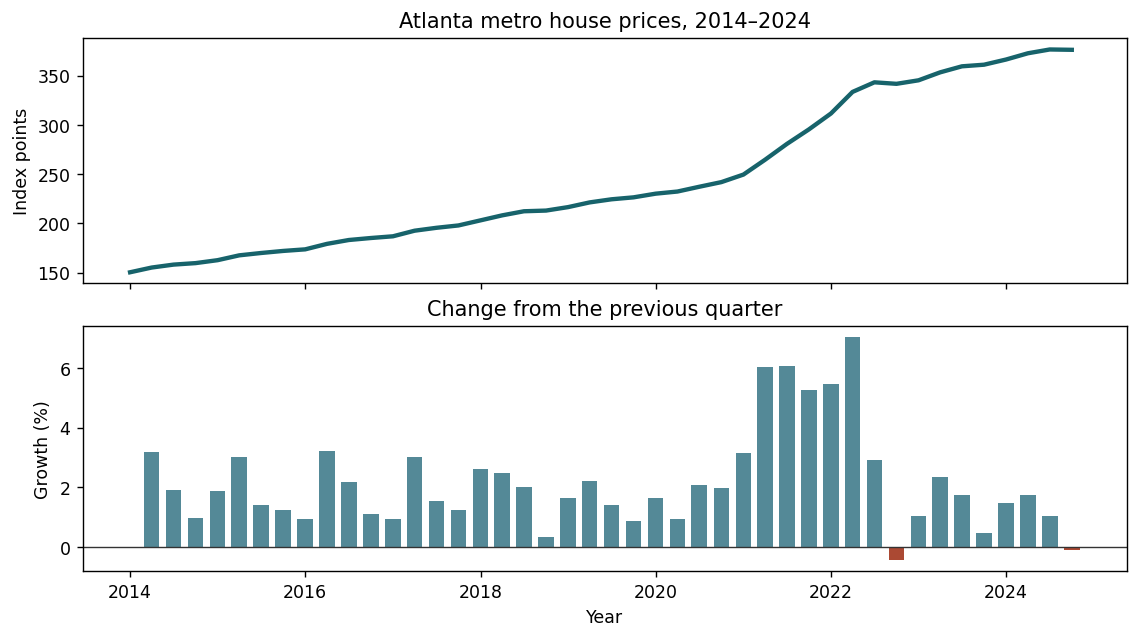

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# One row per year, Q1 to Q4, from 2014 through 2024.
values = [
    150.32, 155.12, 158.10, 159.62,
    162.61, 167.52, 169.90, 171.99,
    173.60, 179.18, 183.10, 185.13,
    186.87, 192.54, 195.49, 197.89,
    203.06, 208.12, 212.30, 212.99,
    216.51, 221.30, 224.45, 226.43,
    230.16, 232.34, 237.19, 241.90,
    249.56, 264.60, 280.66, 295.46,
    311.63, 333.54, 343.28, 341.75,
    345.32, 353.40, 359.53, 361.17,
    366.44, 372.78, 376.64, 376.30,
]
quarters = pd.period_range("2014Q1", periods=len(values), freq="Q")
price = pd.Series(values, index=quarters)

dates = price.index.to_timestamp()
growth = 100 * price.pct_change()
fig, (level, change) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, constrained_layout=True)
level.plot(dates, price, color="#17636b", linewidth=2.5)
level.set(title="Atlanta metro house prices, 2014–2024", ylabel="Index points")
change.bar(dates, growth, width=65, color=["#ab4933" if g < 0 else "#548997" for g in growth])
change.axhline(0, color="#333333", linewidth=0.8)
change.set(title="Change from the previous quarter", ylabel="Growth (%)", xlabel="Year")
plt.show()

### Forecast quarterly growth with an AR(1)

Let $g_t$ be the percentage change in Atlanta’s index this quarter. Estimate $g_{t+1}=a+\phi g_t+\varepsilon_{t+1}$ by regressing growth on its previous value. The fitted slope tells us how much a one-percentage-point increase in current growth changes next quarter’s predicted growth.

For each panel, fit the model using observations through the starting quarter. Predict growth, update the index by multiplying by $1+\hat g/100$, and use the predicted growth as the input for the following quarter. The shaded **80% prediction interval** comes from repeating those steps with randomly sampled fitted residuals. It assumes independent shocks and holds the fitted coefficients fixed.

The left panel checks the forecast against the four observed quarters of 2024. The right panel forecasts 2025 from 2024 Q4. The original metro series ends at that date because FHFA split the geography into two divisions. [FHFA geography change](https://www.fhfa.gov/document/d/hpi/fhfa-house-price-index-report-2025q1)

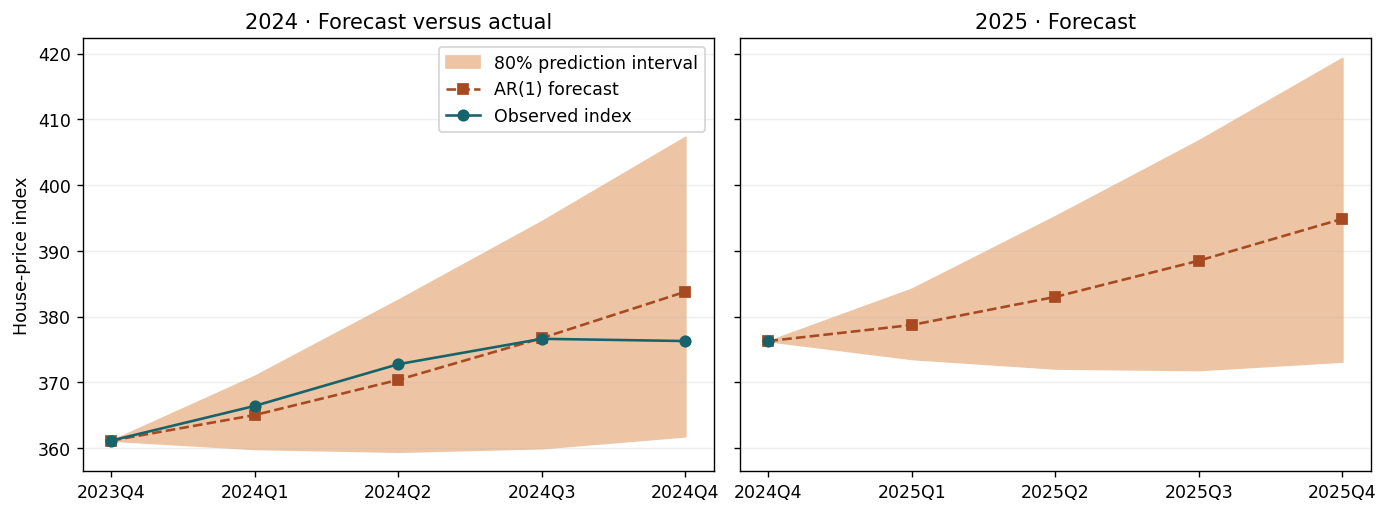

In [2]:
import numpy as np

def forecast_ar1(origin):
    g = growth.loc[:origin].dropna().to_numpy()
    slope, intercept = np.polyfit(g[:-1], g[1:], 1)
    residuals = g[1:] - (intercept + slope * g[:-1])
    rng = np.random.default_rng(422)
    # Column 0 follows the fitted model. The other columns receive shocks.
    shocks = rng.choice(residuals, size=(4, 10_001))
    shocks[:, 0] = 0
    paths = np.full((5, 10_001), price.loc[origin])
    last_growth = g[-1]
    for h in range(4):
        last_growth = intercept + slope * last_growth + shocks[h]
        paths[h+1] = paths[h] * (1 + last_growth / 100)
    lower, upper = np.quantile(paths[:, 1:], [0.10, 0.90], axis=1)
    return paths[:, 0], lower, upper

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
for ax, origin, title in zip(axes, ["2023Q4", "2024Q4"],
                             ["2024 · Forecast versus actual", "2025 · Forecast"]):
    quarters = pd.period_range(origin, periods=5, freq="Q")
    forecast, low, high = forecast_ar1(origin)
    actual = price.reindex(quarters)
    ax.fill_between(range(5), low, high, color="#edc5a4", label="80% prediction interval")
    ax.plot(range(5), forecast, "s--", color="#a74a22", label="AR(1) forecast")
    ax.plot(range(5), actual, "o-", color="#17636b", label="Observed index")
    ax.set(xticks=range(5), xticklabels=quarters.astype(str), title=title)
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("House-price index")
axes[0].legend()
plt.show()

### Satellite data · What does development look like?

The Landsat photographs below show the same northeastern Atlanta suburb in 1984 and 2010. Look for new roads and larger paved areas. To measure that kind of development across a wider area, use the **USGS fractional impervious-surface map**. Its pixel values estimate the percentage of ground covered by materials such as pavement, concrete and rooftops. A value of 40 means about 40% of that pixel is impervious. [NASA photography](https://svs.gsfc.nasa.gov/4062/) · [USGS measurement](https://www.usgs.gov/centers/eros/science/annual-nlcd-fractional-impervious-surface)

In [3]:
# Bundled source data. Run once; the analysis below works offline.
import io, base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
bundle = np.load(io.BytesIO(base64.b64decode('...')))
cities = ["Atlanta", "Charlotte", "Nashville", "Raleigh"]
maps = bundle["maps"].astype(float)
maps[maps == 255] = np.nan  # Outside the ring or missing.
prices = pd.DataFrame(bundle["q4"], index=range(1988, 2025), columns=cities)

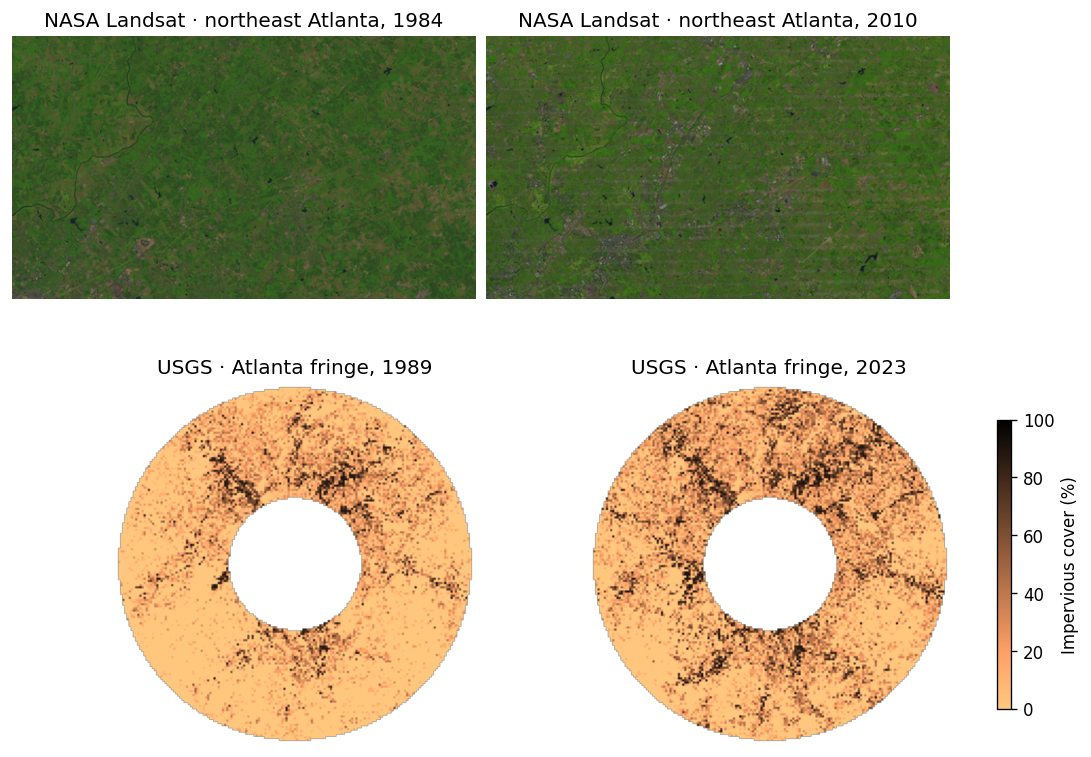

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6.4), constrained_layout=True)
for ax, photo, year in zip(axes[0], bundle["photos"], [1984, 2010]):
    ax.imshow(photo)
    ax.set_title(f"NASA Landsat · northeast Atlanta, {year}")
for ax, grid, year in zip(axes[1], maps[[0, -1], 0], [1989, 2023]):
    image = ax.imshow(grid, cmap="copper_r", vmin=0, vmax=100)
    ax.set_title(f"USGS · Atlanta fringe, {year}")
for ax in axes.flat:
    ax.axis("off")
fig.colorbar(image, ax=axes[1].tolist(), label="Impervious cover (%)", shrink=0.8)
plt.show()

### Extract one economic predictor per metro per year

1. Fix the same **15–40 km ring** around each city center for all years. This approximates its suburban fringe. The upper photographs show one suburb; the lower maps measure the broader ring.
2. Average impervious cover across the same sampled locations each year. For example, a rise from 12.0% to 12.4% means an additional 0.4 percentage points of that area became impervious on net.
3. Take the year-to-year difference. This is the predictor. It can capture construction and associated infrastructure, including commercial development and roads. Its relationship to future housing prices is estimated from the data.

In [5]:
common = np.isfinite(maps).all(axis=0)  # Fixed spatial support across years
cover = pd.DataFrame(np.nanmean(np.where(common, maps, np.nan), axis=(2, 3)),
                     index=range(1989, 2024), columns=cities)
change = cover.diff()
print(pd.DataFrame({"2022 cover (%)": cover.loc[2022], "2023 cover (%)": cover.loc[2023],
                    "Change (pp)": change.loc[2023]}).round(3).to_string())

           2022 cover (%)  2023 cover (%)  Change (pp)
Atlanta            20.817          20.847        0.030
Charlotte          11.791          11.866        0.075
Nashville           7.920           7.962        0.042
Raleigh             9.323           9.411        0.088


### Does the map help forecast next year’s house-price growth?

For a forecast of 2020 growth, use 2019 Q4-to-Q4 price growth and the **2017–2018 change** in impervious cover. This one-year map lag gives the two inputs different information dates. Train on outcomes through 2019 and repeat for every forecast year from 2014 to 2024. Both models use the same training observations, a separate intercept for each metro, and a common slope on lagged growth. Only the second model includes the map variable. Writing $g_{i,t}$ for annual price growth and $S_{i,t}$ for the fringe’s impervious percentage, its forecast is

$$\widehat g_{i,t+1}=\widehat a_i+\widehat\phi g_{i,t}+\widehat\beta(S_{i,t-1}-S_{i,t-2}).$$

If the measured map change is 0.4 percentage points, the fitted satellite term contributes $0.4\widehat\beta$ percentage points to the growth forecast.

This is a **retrospective comparison**. The years follow the earlier exercise’s 2004–2011 scoring period. The USGS collection reconstructs past land cover and was published after many of these forecast dates. The map lag prevents use of future observation years, but historical release vintages would be needed to demonstrate real-time performance.

MAE in percentage points (lower is better)
                 AR(1)  AR(1) + satellite
metro                                    
Atlanta          3.349              3.235
Charlotte        3.655              3.600
Nashville        4.213              4.174
Raleigh          3.883              3.812
All four metros  3.775              3.705


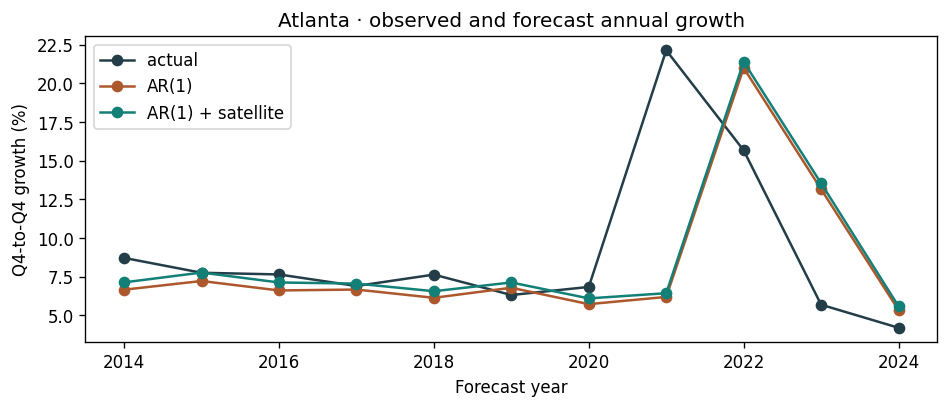

In [6]:
growth = prices.pct_change() * 100
panel = pd.concat({"actual": growth.stack(), "lag_growth": growth.shift(1).stack(),
                   "map_change": change.reindex(growth.index).shift(2).stack()}, axis=1).dropna()
panel.index.names = ["forecast_year", "metro"]
year = panel.index.get_level_values("forecast_year")
intercepts = pd.get_dummies(panel.index.get_level_values("metro"), dtype=float).to_numpy()
baseline = np.column_stack([intercepts, panel.lag_growth])
designs = {"AR(1)": baseline, "AR(1) + satellite": np.column_stack([baseline, panel.map_change])}
results = panel.loc[year >= 2014, ["actual"]].copy()
for name, X in designs.items():
    forecasts = []
    for t in sorted(results.index.get_level_values("forecast_year").unique()):
        coef = np.linalg.lstsq(X[year < t], panel.actual[year < t], rcond=None)[0]
        forecasts.extend(X[year == t] @ coef)
    results[name] = forecasts

errors = results[list(designs)].sub(results.actual, axis=0).abs()
mae = errors.groupby(level="metro").mean()
mae.loc["All four metros"] = errors.mean()
print("MAE in percentage points (lower is better)")
print(mae.round(3).to_string())
ax = results.xs("Atlanta", level="metro").plot(marker="o", figsize=(8, 3.5),
                                                color=["#233e48", "#ad572d", "#138077"])
ax.set(xlabel="Forecast year", ylabel="Q4-to-Q4 growth (%)", title="Atlanta · observed and forecast annual growth")
plt.tight_layout()
plt.show()

**Read the result.** Across 44 metro-year forecasts the mean absolute error was **3.775 percentage points** for AR(1) and **3.705** after adding the satellite measure. The table shows how that pooled result varies across metros. The comparison evaluates predictive accuracy and does not identify a causal effect of construction on prices.

**Data details.** USGS Annual NLCD Collection 1.1 fractional impervious surface, 1989–2023. We sampled one native 30 m pixel every 480 m on a fixed Albers equal-area grid in each ring. The ring centers (longitude, latitude) are Atlanta (−84.388, 33.749), Charlotte (−80.843, 35.227), Nashville (−86.782, 36.163), and Raleigh (−78.639, 35.780). Housing prices are published all-transactions FHFA metropolitan indexes from FRED. [USGS map files](https://source.coop/kylebarron/usgs-landcover) · [Atlanta](https://fred.stlouisfed.org/series/ATNHPIUS12060Q) · [Charlotte](https://fred.stlouisfed.org/series/ATNHPIUS16740Q) · [Nashville](https://fred.stlouisfed.org/series/ATNHPIUS34980Q) · [Raleigh](https://fred.stlouisfed.org/series/ATNHPIUS39580Q)

<div style="border: 2px solid #38716b; border-radius: 8px; padding: 12px 18px; margin: 8px 0;">
<h3>Useful webpages and API keys</h3>
<p><strong>The notebook runs without an API key.</strong> For a first forecast with real data, download monthly metro home values and inventory from <a href="https://www.zillow.com/research/data/">Zillow Research</a>. For a quarterly forecast, use the <a href="https://www.fhfa.gov/data/hpi/datasets">FHFA House Price Index</a>.</p>
<ul>
<li><strong>Connect housing markets.</strong> Download the <a href="https://www.census.gov/data/tables/2020/demo/geographic-mobility/metro-to-metro-migration.html">Census metro-to-metro migration spreadsheet</a> to build the graph. The spreadsheet requires no key.</li>
<li><strong>Add map features.</strong> Start with <a href="https://www.usgs.gov/centers/eros/science/annual-nlcd-data-access">USGS land-cover maps</a> or download <a href="https://developers.google.com/earth-engine/guides/aef_on_gcs_readme">AlphaEarth satellite features</a>. If you process imagery in Google Earth Engine, you need access to a <a href="https://developers.google.com/earth-engine/guides/access">registered Cloud project</a>.</li>
<li><strong>Automate economic data downloads.</strong> Request a <a href="https://fred.stlouisfed.org/docs/api/api_key.html">personal FRED API key</a> to pull mortgage rates or local indicators through the FRED API. Request a <a href="https://api.census.gov/data/key_signup.html">Census Data API key</a> to query metro population or household income from Python. Each key is needed only when using its corresponding API.</li>
</ul>
</div>